# 01 · Cadrage et analyse exploratoire (EDA)
**Projet :** prédire si un réseau électrique sera stable ou instable avant de modifier son réglage.
**Cible :** `stabf` (stable / instable). Classe positive : **instable**.
**Source :** Electrical Grid Stability Simulated Data, UCI id 471 (copie Kaggle). Consultée le : *[date réelle de téléchargement]*.

Ce notebook couvre l'axe 3 : description des données, qualité, cible, relations, audit de fuite.
Chaque graphique est suivi d'une cellule **« Interprétation »** que vous devez rédiger vous-même.

## 1. Imports et chemins

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

RANDOM_STATE = 42                      # graine fixée pour la reproductibilité
DATA_PATH = Path("..") / "data" / "Data_for_UCI_named.csv"   # chemin relatif
sns.set_theme(style="whitegrid")

## 2. Chargement et description

In [2]:
df = pd.read_csv(DATA_PATH)
print("Lignes, colonnes :", df.shape)
df.head()

Lignes, colonnes : (10000, 14)


,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab,stabf
0,2.959060,3.079885,8.381025,9.780754,3.763085,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347,unstable
1,9.304097,4.902524,3.047541,1.369357,5.067812,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957,stable
2,8.971707,8.848428,3.046479,1.214518,3.405158,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471,unstable
3,0.716415,7.669600,4.486641,2.340563,3.963791,-1.027473,-1.938944,-0.997374,0.446209,0.976744,0.929381,0.362718,0.028871,unstable
4,3.134112,7.608772,4.943759,9.857573,3.525811,-1.125531,-1.845975,-0.554305,0.797110,0.455450,0.656947,0.820923,0.049860,unstable


### Dictionnaire des variables
À vérifier dans la documentation UCI (unités et plages exactes).

| Variable | Rôle | Signification |
|---|---|---|
| `tau1` à `tau4` | explicative | temps de réaction du participant (tau1 : producteur, tau2 à tau4 : consommateurs) |
| `p1` à `p4` | explicative | puissance produite (p1 > 0) ou consommée (p2 à p4 < 0) |
| `g1` à `g4` | explicative | sensibilité du participant au prix (élasticité) |
| `stab` | **exclue (fuite)** | marge de stabilité calculée par la simulation : positive = instable |
| `stabf` | **cible** | `stable` ou `unstable`, déduite de `stab` |

## 3. Qualité des données

In [3]:
df.info()
print()
print("Valeurs manquantes par colonne :")
print(df.isna().sum())
print()
print("Lignes dupliquées :", df.duplicated().sum())
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   tau1    10000 non-null  float64
 1   tau2    10000 non-null  float64
 2   tau3    10000 non-null  float64
 3   tau4    10000 non-null  float64
 4   p1      10000 non-null  float64
 5   p2      10000 non-null  float64
 6   p3      10000 non-null  float64
 7   p4      10000 non-null  float64
 8   g1      10000 non-null  float64
 9   g2      10000 non-null  float64
 10  g3      10000 non-null  float64
 11  g4      10000 non-null  float64
 12  stab    10000 non-null  float64
 13  stabf   10000 non-null  str    
dtypes: float64(13), str(1)
memory usage: 1.1 MB

Valeurs manquantes par colonne :
tau1     0
tau2     0
tau3     0
tau4     0
p1       0
p2       0
p3       0
p4       0
g1       0
g2       0
g3       0
g4       0
stab     0
stabf    0
dtype: int64

Lignes dupliquées : 0


,count,mean,std,min,25%,50%,75%,max
tau1,10000.0,5.250000,2.742548,0.500793,2.874892,5.250004,7.624690,9.999469
tau2,10000.0,5.250001,2.742549,0.500141,2.875140,5.249981,7.624893,9.999837
tau3,10000.0,5.250004,2.742549,0.500788,2.875522,5.249979,7.624948,9.999450
tau4,10000.0,5.249997,2.742556,0.500473,2.874950,5.249734,7.624838,9.999443
p1,10000.0,3.750000,0.752160,1.582590,3.218300,3.751025,4.282420,5.864418
p2,10000.0,-1.250000,0.433035,-1.999891,-1.624901,-1.249966,-0.874977,-0.500108
p3,10000.0,-1.250000,0.433035,-1.999945,-1.625025,-1.249974,-0.875043,-0.500072
p4,10000.0,-1.250000,0.433035,-1.999926,-1.624960,-1.250007,-0.875065,-0.500025
g1,10000.0,0.525000,0.274256,0.050009,0.287521,0.525009,0.762435,0.999937
g2,10000.0,0.525000,0.274255,0.050053,0.287552,0.525003,0.762490,0.999944


**Interprétation (à rédiger) :** y a-t-il des valeurs manquantes, des doublons, des valeurs aberrantes ?
Quelle décision prenez-vous, et pourquoi ?
Le jeu compte 10 000 lignes et 14 colonnes, sans valeur manquante ni doublon. Les plages sont régulières (tau de 0,5 à 10, g de 0,05 à 1, p2 à p4 de −2 à −0,5) et les moyennes sont celles d’un tirage uniforme, ce qui confirme des données simulées. Aucun traitement n’est nécessaire.

## 4. La cible : répartition stable / instable

stabf
unstable    6380
stable      3620
Name: count, dtype: int64

stabf
unstable    0.638
stable      0.362
Name: proportion, dtype: float64


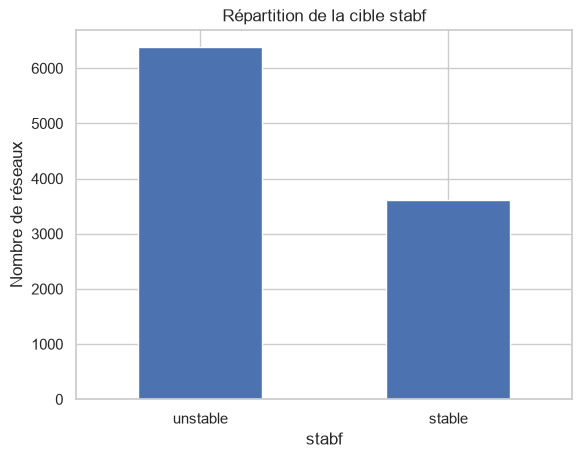

In [4]:
print(df["stabf"].value_counts())
print()
print(df["stabf"].value_counts(normalize=True).round(3))

df["stabf"].value_counts().plot(kind="bar", rot=0,
    title="Répartition de la cible stabf", ylabel="Nombre de réseaux")
plt.show()

**Interprétation (à rédiger) :** les classes sont-elles équilibrées ? Que cela change-t-il pour le split
(stratifié) et pour le choix des métriques (l'accuracy est-elle suffisante ?) ?
63,8 % des réseaux sont instables (6 380) et 36,2 % stables (3 620) : déséquilibre modéré. Un modèle qui répondrait toujours « instable » aurait déjà 63,8 % d’accuracy, qui ne suffit donc pas. Je ferai un split stratifié et je suivrai le recall et la precision sur la classe « instable ».

## 5. Audit de fuite de données

In [5]:
# 5.1 stab est-elle la source de stabf ?
print(df.groupby("stabf")["stab"].agg(["min", "max"]))
coherent = ((df["stab"] > 0) == (df["stabf"] == "unstable")).all()
print("stabf == (stab > 0) sur toutes les lignes ?", coherent)

                   min       max
stabf                           
stable   -8.075989e-02 -0.000002
unstable  2.574273e-07  0.109403
stabf == (stab > 0) sur toutes les lignes ? True


In [6]:
# 5.2 p1 est-elle redondante ? (p1 = -(p2 + p3 + p4))
ecart_max = (df["p1"] + df[["p2", "p3", "p4"]].sum(axis=1)).abs().max()
print("Écart maximal |p1 + p2 + p3 + p4| :", ecart_max)

Écart maximal |p1 + p2 + p3 + p4| : 6.217248937900877e-15


**Conclusion de l'audit (à rédiger) :**
- `stab` : exclue, car elle contient la réponse. Justifiez avec le résultat ci-dessus.
- `p1` : redondante avec p2, p3, p4. Pas une fuite, mais une colinéarité à signaler. Gardez-vous `p1` ? Pourquoi ?
- stab est exclue : elle est négative pour tous les réseaux stables et positive pour tous les instables, donc stabf == (stab > 0) vaut True sur toutes les lignes. La donner au modèle revient à lui donner la réponse. p1 n’est pas une fuite, mais l’écart |p1+p2+p3+p4| est de l’ordre de 6×10⁻¹⁵, soit zéro aux arrondis près : elle est redondante avec p2, p3 et p4.

## 6. Relations entre les variables et la cible

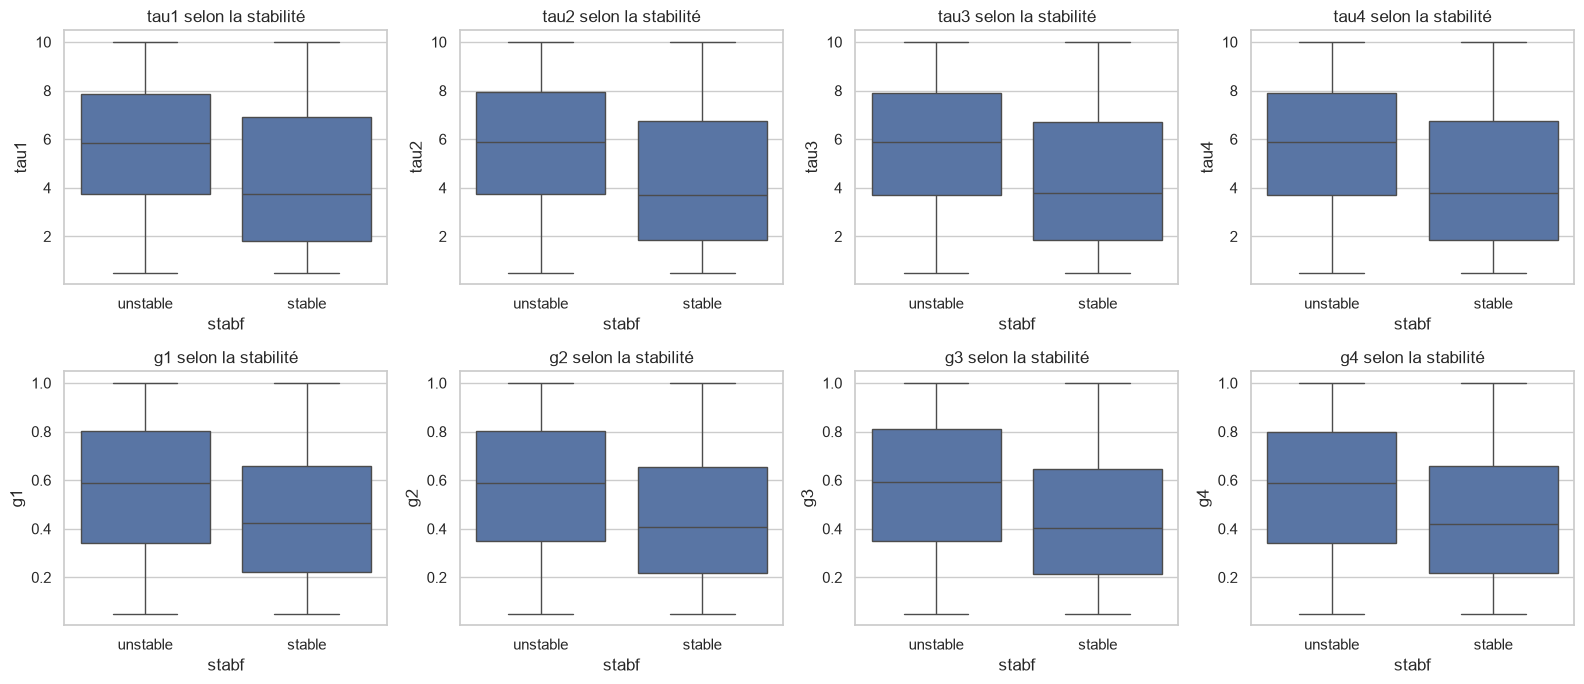

In [7]:
feature_cols = [c for c in df.columns if c not in ("stab", "stabf")]
tau_g_cols = [c for c in feature_cols if c.startswith(("tau", "g"))]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), tau_g_cols):
    sns.boxplot(data=df, x="stabf", y=col, ax=ax)
    ax.set_title(f"{col} selon la stabilité")
plt.tight_layout()
plt.show()

**Interprétation (à rédiger) :** quelles variables semblent différer entre réseaux stables et instables ?
Lesquelles semblent sans effet ?

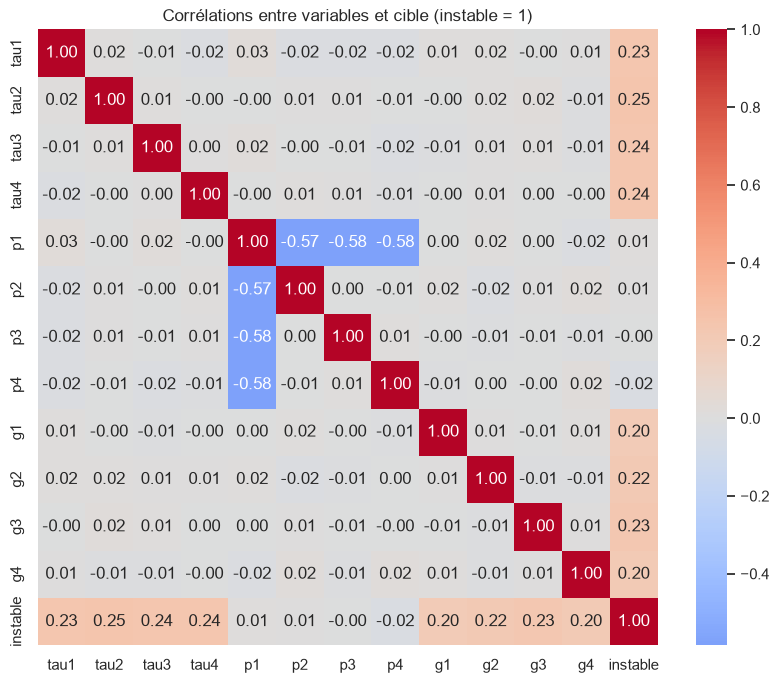

In [8]:
df["instable"] = (df["stabf"] == "unstable").astype(int)   # cible numérique : 1 = instable

corr = df[feature_cols + ["instable"]].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Corrélations entre variables et cible (instable = 1)")
plt.show()

**Interprétation (à rédiger) :** quelles variables sont les plus corrélées à la cible ?
Quelles variables sont corrélées entre elles (voir p1) ?

## 7. Ingénierie de variables (1 à 3 variables, avec justification métier)
À réfléchir : quelle variable construite aurait un sens pour un ingénieur réseau ?
Exemples d'idées : somme ou moyenne des temps de réaction des consommateurs, puissance totale consommée.
Écrivez la justification, puis le code dans la cellule suivante.

In [9]:
# À compléter : création de 1 à 3 variables, par exemple
# df["tau_moyen_conso"] = df[["tau2", "tau3", "tau4"]].mean(axis=1)

## 8. Variables retenues pour la modélisation

In [10]:
X = df[feature_cols]        # explicatives (stab et stabf exclues)
y = df["instable"]          # cible : 1 = instable

print("Variables explicatives :", list(X.columns))
print("Taille de X :", X.shape, "| taille de y :", y.shape)
print("Part d'instables :", round(y.mean(), 3))

Variables explicatives : ['tau1', 'tau2', 'tau3', 'tau4', 'p1', 'p2', 'p3', 'p4', 'g1', 'g2', 'g3', 'g4']
Taille de X : (10000, 12) | taille de y : (10000,)
Part d'instables : 0.638


## Résumé 
Principaux constats, décisions de traitement, variables exclues, ce qui sera fait au notebook 02.